# Lab 1 - Identifier les risques d'un système d'IA

**Objectif.** Construire un petit modèle de prédiction de revenu à partir du jeu de données Adult, puis évaluer ses risques de données, de performance et d'équité. Ce notebook reprend le fil du lab, mais ajoute les contrôles nécessaires pour que le résultat soit vérifiable et réutilisable.

**Attention pédagogique.** Les colonnes `sex` et `race` sont utilisées ici uniquement pour mesurer des écarts entre groupes. Elles ne doivent pas être employées pour décider automatiquement du sort d'une personne. Une métrique d'équité ne prouve pas, à elle seule, qu'un système est équitable : elle déclenche une investigation métier, juridique et technique.

**Pré-requis.** Exécuter d'abord `pip install -r requirements.txt` à la racine du projet. Toutes les cellules marquées **Test** doivent finir sans erreur.

## Comment lire ce notebook

Chaque partie suit le même cycle : **objectif → code → test → interprétation**. Les cellules de code réalisent l'opération ; les cellules **Test** emploient `assert` et stoppent immédiatement le notebook si le résultat est incohérent. Un message `OK` signifie que le contrôle décrit dans la cellule a réussi, pas que le système est automatiquement prêt à être déployé.

L'ordre est important : exécuter les cellules de haut en bas afin que les variables créées à une étape soient disponibles à l'étape suivante. Les sorties (tableaux, métriques, figures) doivent ensuite être commentées, et non simplement copiées dans un rapport.

In [25]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

PROJECT_ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "requirements.txt").exists()), Path.cwd())
ARTIFACTS = PROJECT_ROOT / "notebooks" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)

## 1. Charger et explorer les données

Le jeu Adult n'a pas d'en-tête. On fournit donc la liste des colonnes et on convertit `?` en valeur manquante (`NaN`). Cette conversion est importante : sinon une absence devient une modalité ordinaire et peut influencer silencieusement le modèle.

**Ce que fait le code, ligne par ligne :** `url` indique l'emplacement de la source ; `columns` donne un nom à chaque position du fichier ; `read_csv` crée le tableau Pandas ; `header=None` confirme l'absence de titre dans le fichier ; `na_values="?"` transforme les marqueurs d'absence ; `skipinitialspace=True` élimine les espaces après les virgules. `head()` affiche seulement cinq lignes : ce n'est pas une validation complète, d'où la cellule de test suivante.

In [26]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
columns = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]
data = pd.read_csv(url, header=None, names=columns, na_values="?", skipinitialspace=True)
data.head()

,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [27]:
# Test - intégrité minimale de la source chargée.
assert data.shape[0] > 30_000, "Le jeu Adult attendu contient plus de 30 000 lignes."
assert list(data.columns) == columns
assert set(data["income"].dropna().unique()) == {"<=50K", ">50K"}
print(f"OK - {len(data):,} lignes et {len(columns)} colonnes chargées.")

OK - 32,561 lignes et 15 colonnes chargées.


In [28]:
missing = data.isna().sum().sort_values(ascending=False)
display(missing[missing.gt(0)].to_frame("valeurs_manquantes"))
display(data["income"].value_counts(normalize=True).rename("proportion"))

,valeurs_manquantes
occupation,1843
workclass,1836
native_country,583


income
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64

**Interprétation.** Les valeurs manquantes sont un risque de données : leur fréquence peut différer selon les groupes et altérer la représentation. La distribution de la cible signale ici un déséquilibre : une exactitude élevée pourrait masquer une mauvaise détection de la classe `>50K`.

## 2. Préparer les variables sans fuite de données

La fuite de données apparaît lorsqu'une transformation apprend des statistiques sur le jeu de test. La `Pipeline` ci-dessous ajuste imputation et encodage uniquement sur l'entraînement. Les attributs sensibles sont conservés séparément pour le diagnostic d'équité, mais exclus des variables d'entraînement dans cette démonstration.

**Déroulé :** on copie d'abord les colonnes retenues pour ne pas modifier la table source ; la cible est convertie en `0` / `1` ; `train_test_split` réserve 20 % des données pour l'évaluation ; `stratify=y` conserve une proportion comparable de revenus élevés dans les deux jeux. Les variables numériques reçoivent leur médiane et les variables catégorielles leur modalité la plus fréquente, puis sont encodées. Ces deux transformations vivent dans le pipeline : elles n'apprennent donc jamais sur le test.

In [29]:
features = ["age", "education_num", "hours_per_week", "workclass", "occupation", "marital_status"]
sensitive = ["sex", "race"]
target = "income"
model_data = data[features + sensitive + [target]].copy()
model_data[target] = model_data[target].eq(">50K").astype(int)

X = model_data[features]
y = model_data[target]
X_train, X_test, y_train, y_test, groups_train, groups_test = train_test_split(
    X, y, model_data[sensitive], test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
numeric = ["age", "education_num", "hours_per_week"]
categorical = [c for c in features if c not in numeric]
preprocess = ColumnTransformer([
    ("numeric", Pipeline([("impute", SimpleImputer(strategy="median"))]), numeric),
    ("categorical", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", OneHotEncoder(handle_unknown="ignore"))]), categorical),
])

In [30]:
# Test - séparation exhaustive, sans recouvrement d'indices, et cible stratifiée.
assert len(X_train) + len(X_test) == len(model_data)
assert X_train.index.intersection(X_test.index).empty
assert abs(y_train.mean() - y_test.mean()) < 0.01
assert set(groups_test.columns) == set(sensitive)
print("OK - séparation reproductible et stratifiée.")

OK - séparation reproductible et stratifiée.


## 3. Entraîner et évaluer le modèle

La forêt aléatoire sert de modèle de référence. `random_state` rend l'expérience répétable. On consulte le rapport de classification, l'AUC et la matrice de confusion : aucune métrique seule ne résume tous les risques.

**Comment lire la sortie :** le rapport fournit précision, rappel et F1 par classe. Le rappel de `>50K` répond à « parmi les cas réellement positifs, combien sont détectés ? ». La matrice de confusion montre les faux positifs et faux négatifs, dont le coût dépend du cas d'usage. L'AUC mesure la capacité à ordonner les exemples sur tous les seuils possibles ; elle n'indique ni l'équité ni la conformité.

              precision    recall  f1-score   support

           0      0.868     0.929     0.897      4945
           1      0.711     0.554     0.622      1568

    accuracy                          0.838      6513
   macro avg      0.789     0.741     0.760      6513
weighted avg      0.830     0.838     0.831      6513

AUC ROC : 0.890


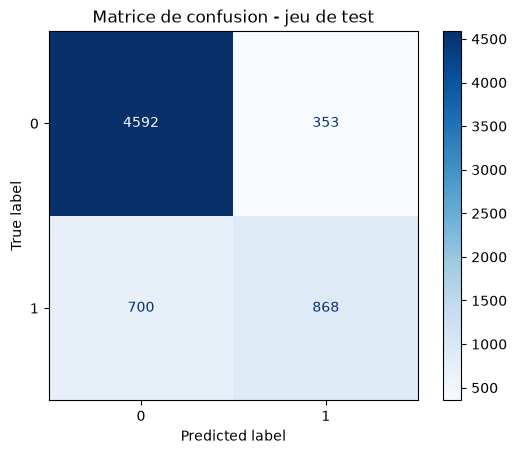

In [31]:
model = Pipeline([
    ("prepare", preprocess),
    ("classifier", RandomForestClassifier(n_estimators=150, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1)),
])
model.fit(X_train, y_train)
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, predictions, digits=3))
print(f"AUC ROC : {roc_auc_score(y_test, probabilities):.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, predictions)).plot(cmap="Blues")
plt.title("Matrice de confusion - jeu de test")
plt.show()

In [32]:
# Test - le pipeline est entraîné et retourne des prédictions binaires alignées.
assert len(predictions) == len(y_test)
assert set(np.unique(predictions)).issubset({0, 1})
assert 0.0 <= roc_auc_score(y_test, probabilities) <= 1.0
print("OK - modèle entraîné et prédictions valides.")

OK - modèle entraîné et prédictions valides.


## 4. Diagnostiquer un écart de sélection par groupe

Le **taux de sélection** est la proportion de prédictions positives. Le ratio de parité compare ce taux à celui du groupe de référence. Un ratio inférieur à 0,80 est souvent utilisé comme signal d'alerte (règle des quatre cinquièmes), mais ce seuil n'est ni une norme universelle ni un verdict légal.

**Lecture du tableau :** `observations` indique la taille de l'échantillon par groupe ; un groupe trop petit rend toute comparaison fragile. `selection_rate` est le taux prédit positif, tandis que `actual_positive_rate` décrit la cible historique - elle peut elle-même porter des biais. Le ratio est calculé par rapport au taux le plus élevé : `1` signifie égalité avec le groupe de référence calculé. Un écart appelle une analyse des données, des critères et du contexte, jamais une conclusion automatique.

In [33]:
audit = groups_test.copy()
audit["prediction"] = predictions
audit["truth"] = y_test
fairness = audit.groupby("sex").agg(
    observations=("prediction", "size"),
    selection_rate=("prediction", "mean"),
    actual_positive_rate=("truth", "mean"),
).sort_index()
reference_rate = fairness["selection_rate"].max()
fairness["selection_parity_ratio"] = fairness["selection_rate"] / reference_rate
display(fairness)

,observations,selection_rate,actual_positive_rate,selection_parity_ratio
sex,,,,
Female,2158,0.062095,0.113531,0.248778
Male,4355,0.249598,0.303789,1.000000


In [34]:
# Test - les taux et ratios sont bornés ; tous les groupes observés sont reportés.
assert not fairness.empty
assert fairness["observations"].gt(0).all()
assert fairness[["selection_rate", "actual_positive_rate", "selection_parity_ratio"]].apply(lambda s: s.between(0, 1).all()).all()
print("OK - diagnostic d'équité calculé pour les groupes observés.")

OK - diagnostic d'équité calculé pour les groupes observés.


## 5. Créer un registre des risques

La priorité est ici `gravité × vraisemblance` (1 à 5). C'est un outil de tri, pas une mesure scientifique. Pour chaque risque, il faut un responsable, un contrôle et une preuve de suivi.

**Étapes du registre :** chaque ligne identifie un risque ; la gravité représente la conséquence potentielle, la vraisemblance sa probabilité estimée ; `priorite` ordonne les sujets à traiter. La colonne `controle` décrit l'action préventive ou détective ; `responsable` rend cette action attribuable. Le fichier CSV exporté peut servir de base à une revue de gouvernance, à condition de dater les évaluations et joindre les preuves.

In [35]:
risk_register = pd.DataFrame([
    ["R-01", "Valeurs manquantes et biais de représentation", "Données", 4, 4, "Imputation dans pipeline; suivi des taux par groupe", "Data owner"],
    ["R-02", "Écart de taux de sélection entre groupes", "Éthique", 5, 4, "Audit d'équité, revue humaine, critères documentés", "Responsible AI lead"],
    ["R-03", "Dérive des données et des performances", "Opérationnel", 4, 3, "Monitoring, seuils d'alerte, revue périodique", "MLOps owner"],
    ["R-04", "Décision insuffisamment explicable", "Gouvernance", 4, 3, "Motifs compréhensibles, procédure de recours", "Product owner"],
], columns=["id", "description", "categorie", "gravite", "vraisemblance", "controle", "responsable"])
risk_register["priorite"] = risk_register["gravite"] * risk_register["vraisemblance"]
risk_register = risk_register.sort_values("priorite", ascending=False)
display(risk_register)
risk_register.to_csv(ARTIFACTS / "lab1_risk_register.csv", index=False)

,id,description,categorie,gravite,vraisemblance,controle,responsable,priorite
1,R-02,Écart de taux de sélection entre groupes,Éthique,5,4,"Audit d'équité, revue humaine, critères docume...",Responsible AI lead,20
0,R-01,Valeurs manquantes et biais de représentation,Données,4,4,Imputation dans pipeline; suivi des taux par g...,Data owner,16
2,R-03,Dérive des données et des performances,Opérationnel,4,3,"Monitoring, seuils d'alerte, revue périodique",MLOps owner,12
3,R-04,Décision insuffisamment explicable,Gouvernance,4,3,"Motifs compréhensibles, procédure de recours",Product owner,12


In [36]:
# Test - registre complet et formule de priorité correcte.
required = {"id", "description", "categorie", "gravite", "vraisemblance", "priorite", "controle", "responsable"}
assert required.issubset(risk_register.columns)
assert (risk_register["priorite"] == risk_register["gravite"] * risk_register["vraisemblance"]).all()
assert (ARTIFACTS / "lab1_risk_register.csv").exists()
print("OK - registre exporté et validé.")

OK - registre exporté et validé.


## Conclusion et questions de réflexion

1. Quel risque devez-vous traiter en premier, et quelle preuve démontrerait que le contrôle fonctionne ?
2. Quels facteurs sociaux ou historiques peuvent expliquer un écart observé, au-delà du code ?
3. Qui peut contester une décision, et sous quel délai ?

Avant tout déploiement, compléter l'analyse par une évaluation d'impact, une validation juridique et une revue avec les personnes concernées.